![title](https://i.imgur.com/XPBIVRh.png)
 <!https://imgur.com/a/weIMgzk>
---



# Task 5 - Variational  AutoEncoder


An **Autoencoder** is a neural network which is an unsupervised learning algorithm which uses back propagation to generate output value which is almost close to the input value. It takes input such as image or vector anything with a very high dimensionality and run through the neural network and tries to compress the data into a smaller representation.

<p align='center'>
<img src='https://www.researchgate.net/profile/Xifeng_Guo/publication/320658590/figure/fig1/AS:614154637418504@1523437284408/The-structure-of-proposed-Convolutional-AutoEncoders-CAE-for-MNIST-In-the-middle-there.png' width=80% />


While the basic idea behind a **Variational Autoencoder** is that instead of mapping an input to fixed vector, input is mapped to a distribution. The only difference between the autoencoder and variational autoencoder is that bottleneck vector is replaced with two different vectors one representing the mean of the distribution and the other representing the standard deviation of the distribution.

<p align='center'>
<img src="https://i.imgur.com/35ckTTI.png" width=80% />

In this notebook we will examine the difference between Vanilla (Convolutional) AutoEncoder and Variational AutoEncoder in generating MNIST images

<!-- https://imgur.com/a/A49UQSI -->

Write down your Name and Student ID

In [1]:
## --- start your code here ----

NIM  = 103012340237
Nama = "Muhammad Hanif Pearlyaradja"

## --- end your code here ----

In [2]:
# --- AUTOGRADESEED05: JANGAN DIHAPUS/DIUBAH ---
# Menghasilkan pengali bobot KL (beta) unik per NIM, dipakai di sanity check
# AUTOGRADECHECK05 di bawah (bukan untuk vae_loss_function() asli yang dipakai
# training 50 epoch - itu tetap pakai beta=1 standar seperti markdown ELBO di
# notebook, supaya Train Loss yang didapat semua mahasiswa bisa dibandingkan
# ke Expected Output yang sama).
import hashlib

SEED = int(hashlib.sha256(str(NIM).strip().encode()).hexdigest(), 16) % (2**31)
BETA_MULT = round(1.0 + (SEED % 50) / 100, 2)  # 1.00 - 1.49

print("Seed (dari NIM):", SEED)
print("Beta (KL weight) multiplier unik (dari NIM):", BETA_MULT)


Seed (dari NIM): 934198153
Beta (KL weight) multiplier unik (dari NIM): 1.03


---
---
#[Part 0] Import Libraries and Load Data

---
## 1 - Import Modul

In the last exercise, we used `Graphviz` and `torchview` to generate a graphical diagram of our network architecture. We also tried the basic `print(model)` command, but the output format wasn't very clean or neat.

Therefore, we will now use the `torchinfo` library to get a better, more structured view of the model architecture.

In [3]:
!pip install torchinfo -q
!pip install graphviz torchview -q

In [4]:
import os
import glob
import argparse
import numpy as np
import matplotlib.pyplot as plt
import imageio.v2 as imageio

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from torchview import draw_graph
from IPython.display import Image, display
from torchinfo import summary

np.set_printoptions(precision=4)

Check target hardware acceleration device

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


---
## 2 - Load MNIST Dataset

Load MNIST dataset and process for minibatch

In [6]:
# Load MNIST Dataset & Normalize
# Converts to [0, 1] and [C, H, W] i.e. (1, 28, 28)
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.MNIST(root='./data', train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Extract numpy arrays for visualization helpers later if needed
x_train = train_dataset.data.numpy().astype('float32') / 255.0
y_train = train_dataset.targets.numpy()
x_test  = test_dataset.data.numpy().astype('float32') / 255.0
y_test  = test_dataset.targets.numpy()

# Create PyTorch DataLoaders
batch_size = 512
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

  0%|          | 0.00/1.65M [00:00<?, ?B/s]

  2%|▏         | 32.8k/1.65M [00:00<00:12, 135kB/s]

  4%|▍         | 65.5k/1.65M [00:00<00:13, 122kB/s]

  8%|▊         | 131k/1.65M [00:00<00:07, 195kB/s] 

 18%|█▊        | 295k/1.65M [00:01<00:03, 364kB/s]

 34%|███▍      | 557k/1.65M [00:01<00:01, 573kB/s]

 66%|██████▌   | 1.08M/1.65M [00:01<00:00, 1.01MB/s]

 99%|█████████▉| 1.64M/1.65M [00:01<00:00, 1.29MB/s]

100%|██████████| 1.65M/1.65M [00:01<00:00, 862kB/s] 

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 7.33MB/s]

---
## 3 - Helper Functions

Below are several helper functions to visualize the generated image

---
### a. Clean Summary
While the `summary` function from Torchinfo is helpful, the output can be quite cluttered because it repeats redundant input and output shapes for both parent and leaf nodes. To fix this, we will use this `clean_summary` function to print a much cleaner version.

In [7]:
def clean_summary(*args, **kwargs):
    # Force torchinfo to show depth so we can read the tree indentation

    kwargs["col_names"] = ["input_size", "output_size", "num_params"]

    stats = summary(*args, **kwargs)
    lines = str(stats).split('\n')

    # Dynamically extract where columns start based on the header line
    header_idx = next(idx for idx, line in enumerate(lines) if "Layer (type" in line)
    header     = lines[header_idx]

    # Find column indices for Input Shape and Output Shape columns
    input_col_start  = header.find("Input Shape")
    num_params_start = header.find("Param #")

    clean_lines = []
    for i in range(len(lines)):
        # Instantly keep all structural decorators, headers, and bottom metric totals
        if "===" in lines[i] or "Total params" in lines[i] or "Layer (type" in lines[i] or "size (MB)" in lines[i]:
            clean_lines.append(lines[i])
            continue

        # Analyze tree depth indents (looking ahead to see if the next row is a child)
        if i + 1 < len(lines):
            current_indent = len(lines[i])   - len(lines[i].lstrip(' │├└'))
            next_indent    = len(lines[i+1]) - len(lines[i+1].lstrip(' │├└'))

            # If the next layer is deeper, this current layer is a parent tree container!
            if next_indent > current_indent:
                # Strip out shapes from the parent line, leaving just its name/tree markings and params
                layer_name_part = lines[i][:input_col_start]
                param_part      = lines[i][num_params_start:]

                # Fill the space between the name and the parameters with empty spaces
                middle_spacing = " " * (num_params_start - input_col_start)

                clean_lines.append(f"{layer_name_part}{middle_spacing}{param_part}")
                continue

        # If it's a leaf node/child node, keep the line exactly as torchinfo generated it
        clean_lines.append(lines[i])

    print('\n'.join(clean_lines))

---
### b. Plot Latent Space

This function visualize the latent space distribution extracted from `encoder` model

In [8]:
def plot_latent_space(encoder_model, x_data, y_data, batch_size=128, vae=False):
    encoder_model.eval()
    z_list = []

    with torch.no_grad():
        # Process in batches to handle memory safely
        for i in range(0, len(x_data), batch_size):
            batch_x = torch.tensor(x_data[i:i+batch_size]).unsqueeze(1).to(device)
            if vae:
                z, _, _ = encoder_model(batch_x)
            else:
                z = encoder_model(batch_x)
            z_list.append(z.cpu().numpy())

    z = np.concatenate(z_list, axis=0)
    print(f'z range: ({np.min(z)}, {np.max(z)})')

    plt.figure(figsize=(12, 10))
    plt.scatter(z[:, 0], z[:, 1], c=y_data, cmap='viridis')
    plt.colorbar()
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.show()


---
### c. Generate Image

This function generate &nbsp;$ n $ &nbsp;images from random latent space &nbsp;$ z $  &nbsp;.

The default range of &nbsp;$ z $  &nbsp; is $(-1..1)$

In [9]:
def generate_image(decoder_model, z_range=(-1,1), n=5):
    decoder_model.eval()
    a, b = z_range
    z_sample = np.random.uniform(a, b, (n, 2)).astype('float32')
    z_tensor = torch.tensor(z_sample).to(device)

    with torch.no_grad():
        x_decoded = decoder_model(z_tensor).cpu().numpy()

    fig, ax = plt.subplots(1, n, figsize=(15, 4.5))
    fig.subplots_adjust(hspace=0.1, wspace=0.1)
    for i in range(n):
        digit = x_decoded[i].reshape(28, 28)
        ax[i].imshow(digit, cmap='gray')
        ax[i].set_title(str(np.round(z_sample[i], 2)))
        ax[i].axis('off')
    plt.show()

---
### d. Plot Interpolating Images
This function generate &nbsp;$n\times n$&nbsp; interpolating images generated from latent space &nbsp;$z$&nbsp;

The default range of &nbsp;$ z $  &nbsp; is $(-1..1)$

In [10]:
def plot_interpolating(decoder_model, z_range=(-1,1), n=20, save=False, filename='img.png', figsize=(10, 10)):
    decoder_model.eval()
    a, b       = z_range
    digit_size = 28
    figure     = np.zeros((digit_size * n, digit_size * n))

    grid_x = np.linspace(a, b, n)
    grid_y = np.linspace(a, b, n)[::-1]

    with torch.no_grad():
        for i, yi in enumerate(grid_y):
            for j, xi in enumerate(grid_x):
                z_sample = torch.tensor([[xi, yi]], dtype=torch.float32).to(device)
                x_decoded = decoder_model(z_sample).cpu().numpy()
                digit = x_decoded[0].reshape(digit_size, digit_size)
                figure[i * digit_size: (i + 1) * digit_size,
                       j * digit_size: (j + 1) * digit_size] = digit

    start_range = digit_size // 2

    # Use list comprehension to guarantee exact match with length n
    pixel_range    = np.array([start_range + i * digit_size for i in range(n)])
    sample_range_x = np.round(grid_x, 1)
    sample_range_y = np.round(grid_y, 1)

    fig = plt.figure(figsize=figsize)
    plt.xticks(pixel_range, sample_range_x)
    plt.yticks(pixel_range, sample_range_y)
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.imshow(figure, cmap='Greys_r')

    if save:
        plt.savefig(filename)
        plt.close(fig)
    else:
        print('range:(', a, ':', b, ')')
        plt.show()

---
### e. Save Image Progress

Function to save interpolating image generated each training epoch

In [11]:
def save_epoch_image(decoder_model, base_dir, epoch, n=10):
    os.makedirs(base_dir, exist_ok=True)
    filename = os.path.join(base_dir, f'image{epoch}.png')
    plot_interpolating(decoder_model, z_range=(-1,1), n=n, save=True, filename=filename, figsize=(5,5))

---
### f. Plot Training Loss

Function to plot the training and validation loss curves over epochs.

In [12]:
def plot_loss(history, title='CAE Model Loss'):
    plt.figure(figsize=(6, 4))

    plt.plot(history['train'], label='Train Loss')
    plt.plot(history['val'], label='Validation Loss')

    plt.title(title)
    plt.ylabel('Loss')
    plt.xlabel('Epoch')

    plt.legend(['Train', 'Val'])
    plt.show()

---
### g. Generate GIF

This function generate a GIF animation formt the saved images

In [13]:
def show_gif(base_dir, anim_file):
    with imageio.get_writer(anim_file, mode='I') as writer:
        filenames = glob.glob(os.path.join(base_dir, 'image*.png'))
        filenames = sorted(filenames, key=lambda x: int(os.path.basename(x).replace('image', '').replace('.png', '')))
        last = -1
        for i, filename in enumerate(filenames):
            frame = (i**0.5)
            if round(frame) > round(last):
                last = frame
            else:
                continue
            image = imageio.imread(filename)
            writer.append_data(image)
            writer.append_data(image)
        if filenames:
            image = imageio.imread(filenames[-1])
            writer.append_data(image)
    print('GIF saved as', anim_file)

---
---
# [Part 1] Convolutional AutoEncoder

Now let's build our Convolutional AutoEncoder

<center>
<img src='https://miro.medium.com/max/1578/1*bY_ShNK6lBCQ3D9LYIfwJg@2x.png' width=60%>

---
## 1 - Conv-AE Encoder

First, define the Encoder model

The architechture is as follow:
<pre>
    * The input shape is 3-dimensional <font color='blue'><b>(1, 28,28)</b></font>  
    * Strided Convolutional (Downsampling) Block:
      * <b>conv</b> layer with <font color='blue'><b>32</b></font> filters of <font color='blue'><b>3x3</b></font>, using stride <font color='blue'><b>2</b></font> and relu activation
      * <b>conv</b> layer with <font color='blue'><b>64</b></font> filters of <font color='blue'><b>3x3</b></font>, using stride <font color='blue'><b>2</b></font> and relu activation
    * Flatten layer
    * Dense Bottleneck Block:
      * <b>Linear</b> layer with <font color='blue'><b>16</b></font> neurons and relu activation
      * output <b>Linear</b> layer with <font color='blue'><b>2</b></font> neuron without activation
</pre>

---
#### <font color='red'>**EXERCISE:** </font>

    build the encoder model
    - complete the layer and building blocks definition
    - complete the `forward` function

    Note: The input shape is (1, 28,28)  

In [14]:
class ConvAE_Encoder(nn.Module):
    def __init__(self):
        super(ConvAE_Encoder, self).__init__()

        # Strided Convolutional block
        self.conv_block = nn.Sequential(
            # add conv2d layer with 32 filters of 3x3, using stride 2, and padding 1
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),

            # add relu
            nn.ReLU(),

            # add conv2d layer with 64 filters of 3x3, using stride 2, and padding 1,
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),

            # add relu
            nn.ReLU()
        )

        # add flatten layer
        self.flatten = nn.Flatten()

        # Dense Bottleneck block
        self.bottleneck_block = nn.Sequential(
            # add Linear with input features 64*7*7 and output 16 neurons
            nn.Linear(64*7*7, 16),

            # add relu
            nn.ReLU(),

            # add Linear with input features 16 and output 2 neurons
            nn.Linear(16, 2)
        )

    def forward(self, x):

        # pass x through self.conv_block(), self.flatten(), and self.bottleneck_block() in that order
        x = self.conv_block(x)

        x = self.flatten(x)

        x = self.bottleneck_block(x)

        return x

Instantiate `encoder` model, and print the model architecture using `clean_summary` function


In [15]:
ae_encoder = ConvAE_Encoder().to(device)

clean_summary(ae_encoder, input_size=(1, 1, 28, 28))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ConvAE_Encoder                                                                               --
├─Sequential: 1-1                                                                            --
│    └─Conv2d: 2-1                       [1, 1, 28, 28]            [1, 32, 14, 14]           320
│    └─ReLU: 2-2                         [1, 32, 14, 14]           [1, 32, 14, 14]           --
│    └─Conv2d: 2-3                       [1, 32, 14, 14]           [1, 64, 7, 7]             18,496
│    └─ReLU: 2-4                         [1, 64, 7, 7]             [1, 64, 7, 7]             --
├─Flatten: 1-2                           [1, 64, 7, 7]             [1, 3136]                 --
├─Sequential: 1-3                                                                            --
│    └─Linear: 2-5                       [1, 3136]                 [1, 16]                   50,192
│    └─ReLU: 2-6          

**EXPECTED OUTPUT**:
<pre>
===================================================================================================================
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
===================================================================================================================
ConvAE_Encoder                                                                               --
├─Sequential: 1-1                                                                            --
│    └─Conv2d: 2-1                       [1, 1, 28, 28]            [1, 32, 14, 14]           320
│    └─ReLU: 2-2                         [1, 32, 14, 14]           [1, 32, 14, 14]           --
│    └─Conv2d: 2-3                       [1, 32, 14, 14]           [1, 64, 7, 7]             18,496
│    └─ReLU: 2-4                         [1, 64, 7, 7]             [1, 64, 7, 7]             --
├─Flatten: 1-2                           [1, 64, 7, 7]             [1, 3136]                 --
├─Sequential: 1-3                                                                            --
│    └─Linear: 2-5                       [1, 3136]                 [1, 16]                   50,192
│    └─ReLU: 2-6                         [1, 16]                   [1, 16]                   --
│    └─Linear: 2-7                       [1, 16]                   [1, 2]                    34
===================================================================================================================
Total params: 69,042
Trainable params: 69,042

Visualize the network architecture in graphical form.

Click the image to enlarge


(process:15380): Pango-WARNING **: 19:30:58.781: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


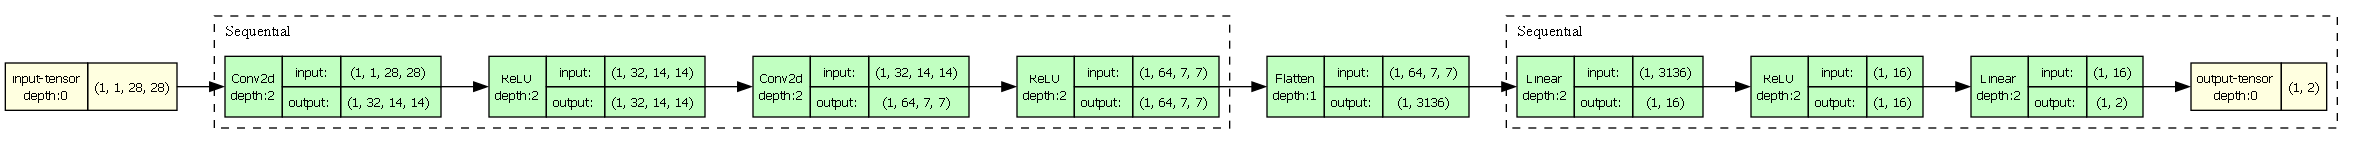

In [16]:
model_graphq = draw_graph(ae_encoder, input_size=(1, 1, 28, 28), expand_nested=True, graph_dir="LR")
model_graphq.resize_graph(scale=3)

model_graphq.visual_graph.render("ae_encoder", format="png")
display(Image(filename="ae_encoder.png"))

**Expected Output**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/rnvqvQY.png" width="800">

---
## 2 - Conv-AE Decoder

Next, we define the Decoder model

The architechture is as follow:
<pre>
    * The input shape is 1-dimensional <font color='blue'><b>(1,2)</b></font>
    * Dense Projection Block:
      * <b>Linear</b> layer with <font color='blue'><b>64*7*7</b></font> neurons and relu activation
    * reshape to convert input into <font color='blue'><b>(64,7,7)</b></font> 3-dimensional matrix
    * Upsampling Deconv Block:
      * <b>ConvTranspose2d</b> layer with <font color='blue'><b>64</b></font> filters of <font color='blue'><b>3x3</b></font>, using stride <font color='blue'><b>2</b></font> and relu activation
      * <b>ConvTranspose2d</b> layer with <font color='blue'><b>32</b></font> filters of <font color='blue'><b>3x3</b></font>, using stride <font color='blue'><b>2</b></font> and relu activation
      * output <b>ConvTranspose2d</b> layer with <font color='blue'><b>1</b></font> filters of <font color='blue'><b>3x3</b></font> and <b>sigmoid</b> activation
</pre>

---
#### <font color='red'>**EXERCISE:** </font>

    build the decoder model
    - complete the layer and building blocks definition
    - complete the `forward` function

In [17]:
class ConvAE_Decoder(nn.Module):
    def __init__(self):
        super(ConvAE_Decoder, self).__init__()

        # Dense Projection block
        self.projection_block = nn.Sequential(
            # add Linear with input features 2 and output feature 64*7*7 neurons
            nn.Linear(2, 64*7*7),

            # add relu
            nn.ReLU()
        )

        # Upsampling Deconv Block
        self.deconv_block = nn.Sequential(
            # add ConvTranspose2d layer with 64 filters of 3x3, using stride 2, padding 1, and output_padding 1,
            nn.ConvTranspose2d(64, 64, kernel_size=3, stride=2, padding=1, output_padding=1),

            # add relu
            nn.ReLU(),

            # add ConvTranspose2d layer with 32 filters of 3x3, using stride 2, padding 1, and output_padding 1,
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),

            # add relu
            nn.ReLU(),

            # add ConvTranspose2d layer with 1 filters of 3x3, using stride 1, and padding 1,
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=1, padding=1),

            # add Sigmoid
            nn.Sigmoid()
        )

    def forward(self, z):
        # pass z through self.projection_block()
        x = self.projection_block(z)

        # reshape x into (64,7,7) 3-dimensional matrix
        x = x.view(-1, 64, 7, 7)

        # pass x through self.deconv_block()
        x = self.deconv_block(x)

        return x


Instantiate `decoder` model, and print the model architecture using `clean_summary` function


In [18]:
ae_decoder = ConvAE_Decoder().to(device)

clean_summary(ae_decoder, input_size=(1, 2))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ConvAE_Decoder                                                                               --
├─Sequential: 1-1                                                                            --
│    └─Linear: 2-1                       [1, 2]                    [1, 3136]                 9,408
│    └─ReLU: 2-2                         [1, 3136]                 [1, 3136]                 --
├─Sequential: 1-2                                                                            --
│    └─ConvTranspose2d: 2-3              [1, 64, 7, 7]             [1, 64, 14, 14]           36,928
│    └─ReLU: 2-4                         [1, 64, 14, 14]           [1, 64, 14, 14]           --
│    └─ConvTranspose2d: 2-5              [1, 64, 14, 14]           [1, 32, 28, 28]           18,464
│    └─ReLU: 2-6                         [1, 32, 28, 28]           [1, 32, 28, 28]           --
│    └─ConvTranspose2d: 

**EXPECTED OUTPUT**:
<pre>
===================================================================================================================
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
===================================================================================================================
ConvAE_Decoder                                                                               --
├─Sequential: 1-1                                                                            --
│    └─Linear: 2-1                       [1, 2]                    [1, 3136]                 9,408
│    └─ReLU: 2-2                         [1, 3136]                 [1, 3136]                 --
├─Sequential: 1-2                                                                            --
│    └─ConvTranspose2d: 2-3              [1, 64, 7, 7]             [1, 64, 14, 14]           36,928
│    └─ReLU: 2-4                         [1, 64, 14, 14]           [1, 64, 14, 14]           --
│    └─ConvTranspose2d: 2-5              [1, 64, 14, 14]           [1, 32, 28, 28]           18,464
│    └─ReLU: 2-6                         [1, 32, 28, 28]           [1, 32, 28, 28]           --
│    └─ConvTranspose2d: 2-7              [1, 32, 28, 28]           [1, 1, 28, 28]            289
│    └─Sigmoid: 2-8                      [1, 1, 28, 28]            [1, 1, 28, 28]            --
===================================================================================================================
Total params: 65,089
Trainable params: 65,089

Visualize the network architecture in graphical form.

Click the image to enlarge


(process:4664): Pango-WARNING **: 19:30:59.581: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


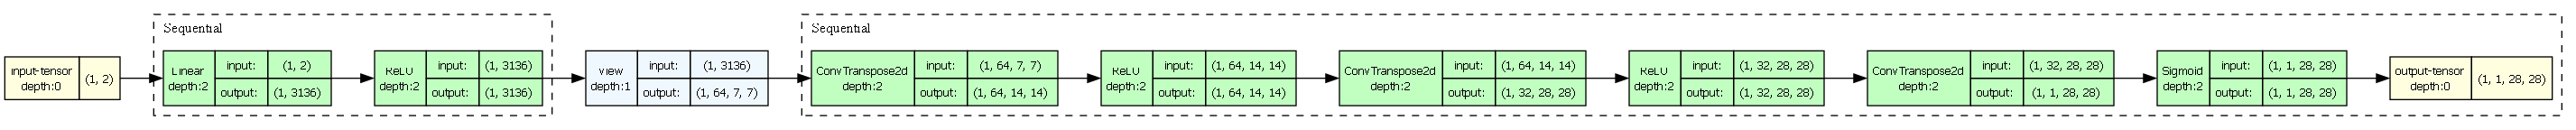

In [19]:
model_graphq = draw_graph(ae_decoder, input_size=(1, 2), expand_nested=True, graph_dir="LR")
model_graphq.resize_graph(scale=3)

model_graphq.visual_graph.render("ae_decoder", format="png")
display(Image(filename="ae_decoder.png"))

**Expected Output**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/niZonlv.png" width="800">

---
## 3 - Conv-AutoEncoder

Lastly, we combine the Encoder and Decoder into single AutoEncoder model

---

#### <font color='red'>**EXERCISE:** </font>
    build the full DCAE model
    - complete the layer and building blocks definition
    - complete the `forward` function

    should be self explanatory

In [20]:
class ConvolutionalAutoencoder(nn.Module):
    def __init__(self, encoder, decoder):
        super(ConvolutionalAutoencoder, self).__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):

        # pass x through self.encoder()
        z = self.encoder(x)

        # pass z through self.decoder()
        x_recon = self.decoder(z)

        return x_recon


Instantiate our `autoencoder` model, and print the model architecture using `clean_summary` function


In [21]:
ae_model = ConvolutionalAutoencoder(ae_encoder, ae_decoder).to(device)

clean_summary(ae_model, input_size=(1, 1, 28, 28), depth=2)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
ConvolutionalAutoencoder                                                                     --
├─ConvAE_Encoder: 1-1                                                                        --
│    └─Sequential: 2-1                   [1, 1, 28, 28]            [1, 64, 7, 7]             18,816
│    └─Flatten: 2-2                      [1, 64, 7, 7]             [1, 3136]                 --
│    └─Sequential: 2-3                   [1, 3136]                 [1, 2]                    50,226
├─ConvAE_Decoder: 1-2                                                                        --
│    └─Sequential: 2-4                   [1, 2]                    [1, 3136]                 9,408
│    └─Sequential: 2-5                   [1, 64, 7, 7]             [1, 1, 28, 28]            55,681
Total params: 134,131
Trainable params: 134,131
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 22.97
Inp

**EXPECTED OUTPUT**:
<pre>
===================================================================================================================
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
===================================================================================================================
ConvolutionalAutoencoder                                                                     --
├─ConvAE_Encoder: 1-1                                                                        --
│    └─Sequential: 2-1                   [1, 1, 28, 28]            [1, 64, 7, 7]             18,816
│    └─Flatten: 2-2                      [1, 64, 7, 7]             [1, 3136]                 --
│    └─Sequential: 2-3                   [1, 3136]                 [1, 2]                    50,226
├─ConvAE_Decoder: 1-2                                                                        --
│    └─Sequential: 2-4                   [1, 2]                    [1, 3136]                 9,408
│    └─Sequential: 2-5                   [1, 64, 7, 7]             [1, 1, 28, 28]            55,681
===================================================================================================================
Total params: 134,131
Trainable params: 134,131

Visualize the network architecture

Click the image to enlarge


(process:9584): Pango-WARNING **: 19:31:00.332: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


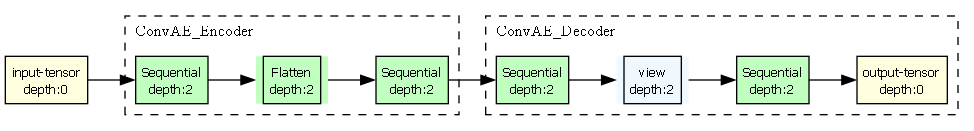

In [22]:
model_graphq = draw_graph(ae_model, input_size=(1, 1, 28, 28), expand_nested=True, show_shapes=False, depth=2, graph_dir="LR" )
model_graphq.resize_graph(scale=3)

model_graphq.visual_graph.render("conv_autoencoder", format="png")
display(Image(filename="conv_autoencoder.png"))

**Expected Output**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/EMuimOF.png" width="800">

---
## 4 - Train Convolutional AutoEncoder

The next step is to train the model

---
### a. Training Loop

Complete the `train_model` function by implementing the standard PyTorch optimization steps inside the batch loop, but now with `validation` phase

---
#### <font color='red'>**EXERCISE:** </font>
    - Complete the `train_model` function

In [23]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs, base_dir):
    train_loss_history = []
    val_loss_history   = []

    print('Start Training')

    for epoch in range(1, epochs + 1):
        # ==================== TRAINING PHASE ====================
        model.train()
        running_loss = 0.0
        for inputs, _ in train_loader:
            inputs = inputs.to(device)

            # Zero out accumulated gradients for the variables which the optimizer
            # call zero_grad() from optimizer
            optimizer.zero_grad()

            # Forward pass output
            # call model() with input inputs
            outputs = model(inputs)

            # Calculate Loss
            # call criterion() with inputs: outputs and inputs
            loss = criterion(outputs, inputs)

            # Backward pass to compute the gradients
            # call backward() function from loss
            loss.backward()

            # Update weights using the optimizer step
            # call step() function from optimizer
            optimizer.step()

            # multiply loss.item() by inputs.size(0) and add to running_loss
            running_loss += loss.item() * inputs.size(0)

        epoch_train_loss = running_loss / len(train_loader.dataset)
        train_loss_history.append(epoch_train_loss)


        # ==================== VALIDATION PHASE ====================
        # set model to eval mode
        model.eval()
        running_val_loss = 0.0

        # stop gradient calculation
        with torch.no_grad():
            for val_inputs, _ in val_loader:
                val_inputs = val_inputs.to(device)

                # Forward pass output
                # call model() with input val_inputs
                val_outputs = model(val_inputs)

                # Calculate Loss
                # call criterion() with inputs: val_outputs and val_inputs
                val_loss = criterion(val_outputs, val_inputs)

                # multiply val_loss.item() by val_inputs.size(0) and add to running_val_loss
                running_val_loss += val_loss.item() * val_inputs.size(0)

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        val_loss_history.append(epoch_val_loss)

        # ==================== LOGGING & SAVING ====================

        # Save Image every epoch
        save_epoch_image(model.decoder, base_dir, epoch, n=12)

        if epoch % 2 == 0 or epoch == 1:
            print(f"Epoch [{epoch}/{epochs}], "
                  f"Train Loss: {epoch_train_loss:.4f}, "
                  f"Val Loss: {epoch_val_loss:.4f}")

    print('Training Done')

    return {
        'train': train_loss_history,
        'val': val_loss_history
    }

---
### b. Train DC-AE

Train the Autoencoder model for 50 epochs.
We'll use MNIST test set for validation

Training will take about 10 minutes. Just sit back and enjoy some snacks!

In [24]:
ae_criterion = nn.BCELoss(reduction='mean')
ae_optimizer = optim.Adam(ae_model.parameters(), lr=1e-3)

epochs = 50
base_dir_ae = 'conv_ae'

ae_history = train_model(ae_model, train_loader, test_loader,
                         ae_criterion, ae_optimizer, epochs,
                         base_dir_ae)

Start Training


Epoch [1/50], Train Loss: 0.2905, Val Loss: 0.2285


Epoch [2/50], Train Loss: 0.2197, Val Loss: 0.2144


Epoch [4/50], Train Loss: 0.2074, Val Loss: 0.2075


Epoch [6/50], Train Loss: 0.2007, Val Loss: 0.1981


Epoch [8/50], Train Loss: 0.1964, Val Loss: 0.1947


... (17 outputs left out)

Epoch [44/50], Train Loss: 0.1804, Val Loss: 0.1814


Epoch [46/50], Train Loss: 0.1799, Val Loss: 0.1808


Epoch [48/50], Train Loss: 0.1795, Val Loss: 0.1838


Epoch [50/50], Train Loss: 0.1792, Val Loss: 0.1812
Training Done


**EXPECTED OUTPUT**:
<pre>
Train Loss should start at around 0.30 and ends at around 0.18 in 50 epochs.
Train more to get better result.

---
### c. Visualize Loss History

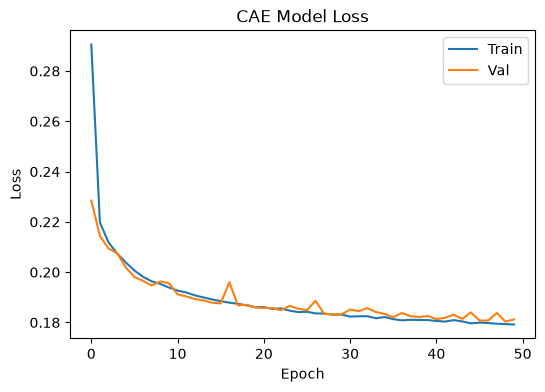

In [25]:
plot_loss(ae_history)

---
## 5 - Visualize Generated Images

Now let's visualize the result

---
### a. Latent Space Distribution

Plots labels and MNIST digits as function of 2-dim latent vector

You should see that the distribution of latent vector is clustered by class as AutoEncoder is intended to perform Dimensionality Reduction or Feature Extraction

The clustered distribution is good for Classification purposes, but not for Image Generation

z range: (-6.392961502075195, 11.129427909851074)


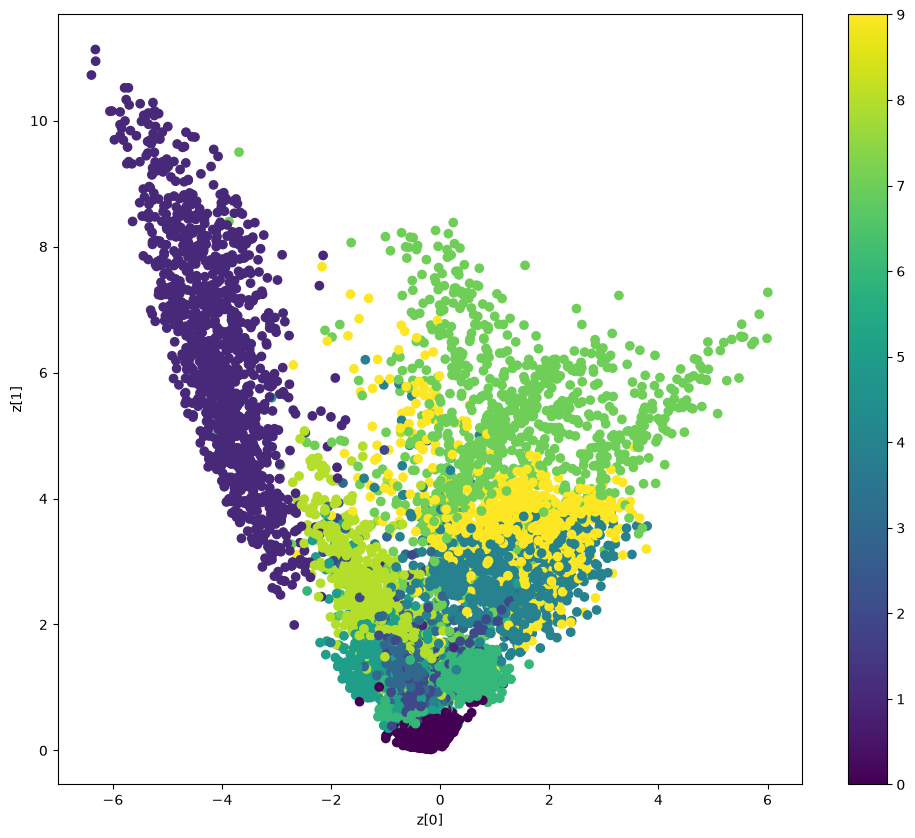

In [26]:
plot_latent_space(ae_encoder, x_test, y_test, vae=False)

**EXPECTED OUTPUT**:
<pre>
output image should be something like these

<img src="https://i.imgur.com/xbGKfy7.png" height="300"> or <img src="https://i.imgur.com/u2VqMh8.png" height="300">



---
### b. Reconstructed Images

Next, let's visualzie the Reconstructed Images from several data test

You'll see that using shallow ConvNet and several epochs, we can already perform dimensionality reduction, and reconstruct the reduced data back into its original image

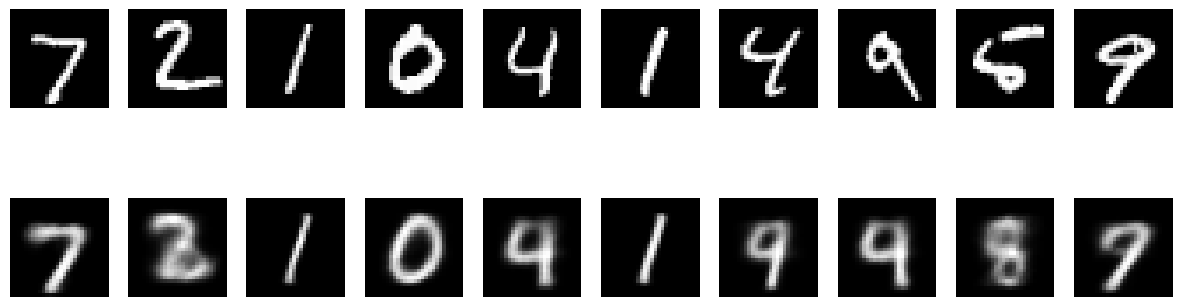

In [27]:
ae_model.eval()
with torch.no_grad():
    ori_img_tensor = torch.tensor(x_test[:10]).unsqueeze(1).to(device)
    rec_img_tensor = ae_model(ori_img_tensor).cpu().numpy()

fig, ax = plt.subplots(2, 10, figsize=(15, 4.5))
for i in range(10):
    ax[0, i].imshow(x_test[i], cmap='gray')
    ax[0, i].axis('off')
    ax[1, i].imshow(rec_img_tensor[i].reshape(28, 28), cmap='gray')
    ax[1, i].axis('off')
plt.show()

**EXPECTED OUTPUT**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/XxWS4Ip.png" width="600">

---
### c. Randomly Generated

Now let's try to generate &nbsp;$5$&nbsp; new images from a random latent vector &nbsp;$z$&nbsp;

You should see that the result is quite good

The network is able to generate new image from random input

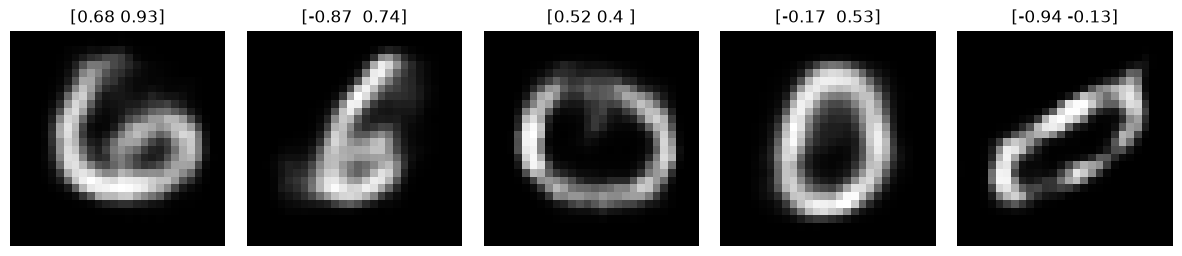

In [28]:
generate_image(ae_decoder, z_range=(-1, 1))

**EXPECTED OUTPUT**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/QylcnIQ.png" width="400">

But what happened if we try to widen the vector random range to $(-5..5)$?

You might see that some images get corrupted because the decoder model is not trained to generate images in that input area

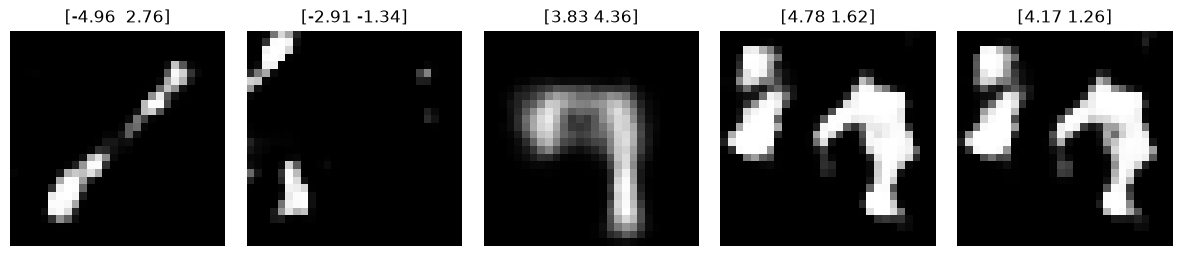

In [29]:
generate_image(ae_decoder, z_range=(-5, 5))

**EXPECTED OUTPUT**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/SbmQxsY.png" width="400">

You can try to generate single image by running the cell below

you can use predefined latent vector or generate a random vector

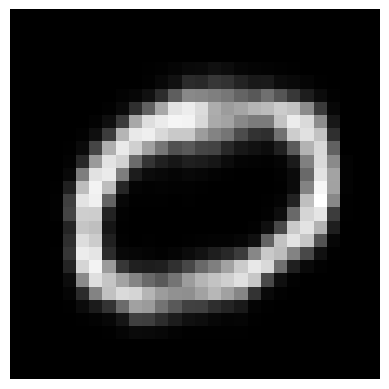

In [30]:
z_sample = np.array([[0,0]])

ae_decoder.eval()
with torch.no_grad():
    z_sample = torch.tensor(z_sample, dtype=torch.float32).to(device)
    x_decoded = ae_decoder(z_sample).cpu().numpy()
digit = x_decoded.reshape(28, 28)
plt.imshow(digit, cmap='gray')
plt.axis('off')
plt.show()

---
### d. Plot Interpolation

Now let's generate the image interpolation generated from a range of latent vectors

First we generate $10\times 10$ image ranged from $(-1..1)$

range:( -1 : 1 )


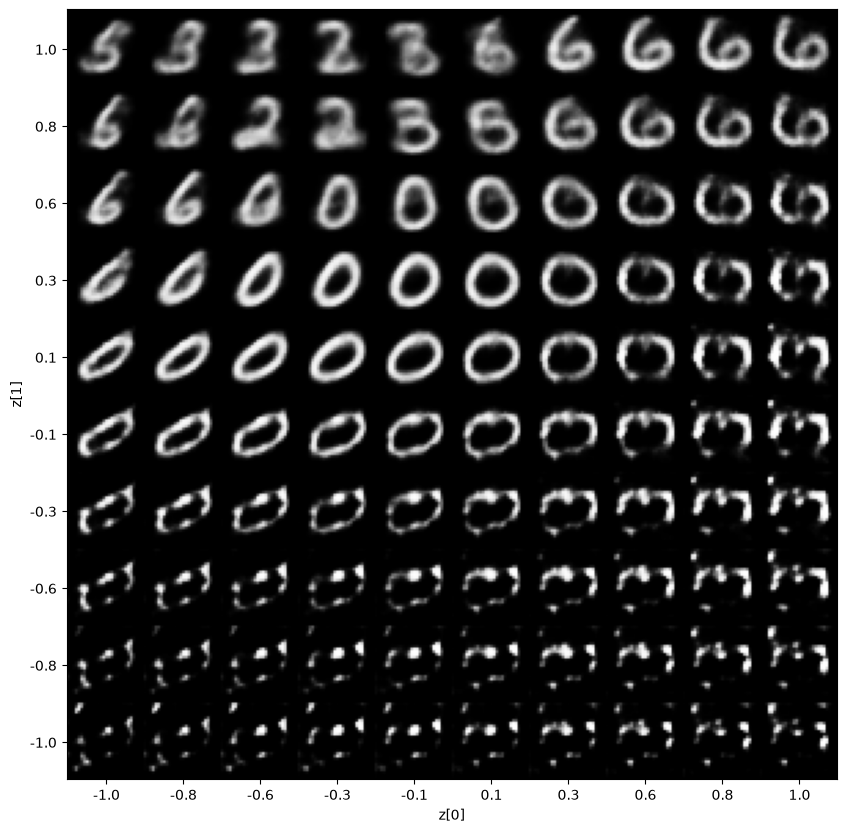

In [31]:
plot_interpolating(ae_decoder, n=10)

**EXPECTED OUTPUT**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/ZlwsBy6.png" height="300">

Now let's try to widen the range. For that we deepen the interpolation to $20\times 20$

Again, you may notice that in some input ranges, the generated images begin to be unrecognizable

range:( -10 : 10 )


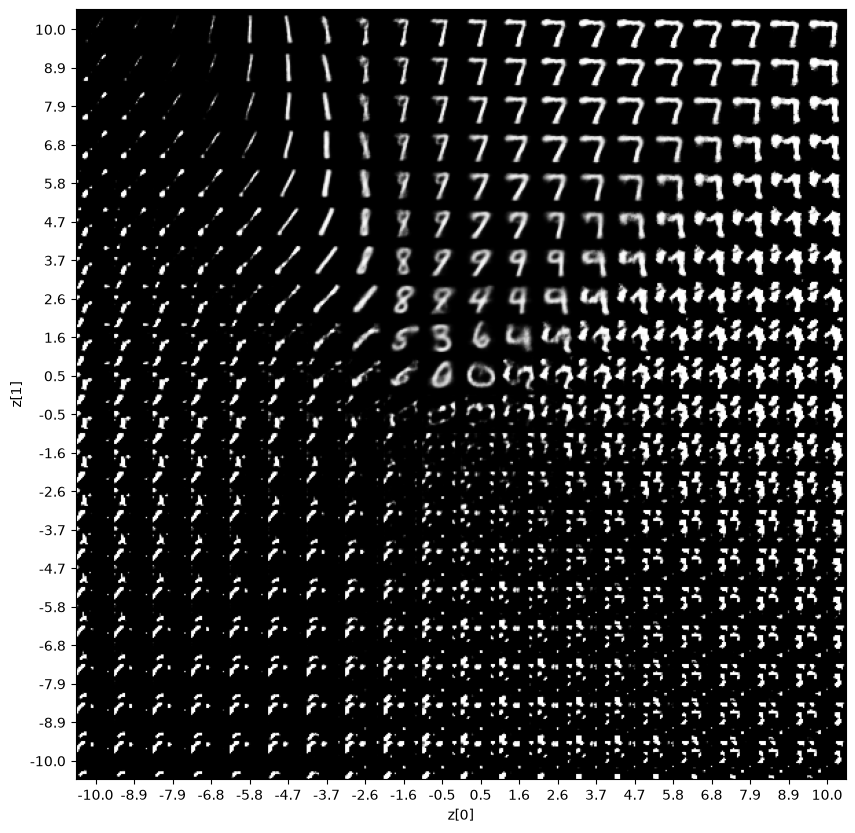

In [32]:
plot_interpolating(ae_decoder, n=20, z_range=(-10,10))

**EXPECTED OUTPUT**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/d5SFiUQ.png" height="300">

---
### e. Generate GIF

Now this just for fun, we combine the saved image generated each epoch while training into a GIF animation

open the result in Files tab

In [33]:
show_gif(base_dir_ae, 'conv_autoenc.gif')

GIF saved as conv_autoenc.gif


---
---
# [Part 2] Variational AutoEncoder

As already mentioned before, the basic idea behind a **Variational Autoencoder** is that instead of mapping an input to fixed vector, input is mapped to a distribution.

A variational autoencoder can be defined as being an autoencoder whose training is regularised to avoid overfitting and ensure that the latent space has good properties that enable generative process.

<p align='center'>
<img src="https://miro.medium.com/max/3374/1*22cSCfmktNIwH5m__u2ffA.png" width=80% />

The only difference between the autoencoder and variational autoencoder is that bottleneck vector is replaced with two different vectors one representing the mean of the distribution and the other representing the standard deviation of the distribution.



---
## 1 - VAE Encoder

This defines the generative model which takes a latent encoding as input, and outputs the parameters for a conditional distribution of the observation, i.e. $p(x|z)$. Additionally, we use a unit Gaussian prior $p(z)$ for the latent variable.

<center>
<img src='https://miro.medium.com/max/1608/1*XYyWimolMhPDMg8qCNlcwg@2x.png' width=60%>
</center>

Now to define the Encoder model. Two-third of it is pretty much the same as normal Encoder

The architechture is as follow:
<pre>
    * the input shape is 3-dimensional <font color='blue'><b>(1,28,28)</b></font>  
    * Strided Convolutional (Downsampling) Block:
      * <b>conv</b> layer with <font color='blue'><b>32</b></font> filters of <font color='blue'><b>3x3</b></font>, using stride <font color='blue'><b>2</b></font> and relu activation
      * <b>conv</b> layer with <font color='blue'><b>64</b></font> filters of <font color='blue'><b>3x3</b></font>, using stride <font color='blue'><b>2</b></font> and relu activation
    * Flatten layer
    * Dense Bottleneck Block:
      * <b>Linear</b> layer with <font color='blue'><b>16</b></font> neurons and relu activation
    * z_mean output: <b>Linear</b> layer with <font color='blue'><b>2</b></font> neuron without activation
    * z_log_var output: <b>Linear</b> layer with <font color='blue'><b>2</b></font> neuron without activation
</pre>

---
#### <font color='red'>**EXERCISE:** </font>

    build the VAE encoder model
    - complete the layer and building blocks definition
    - complete the `forward` function

    Note: The input shape is (1, 28,28)  

In [34]:
class VAE_Encoder(nn.Module):
    def __init__(self):
        super(VAE_Encoder, self).__init__()

        # Strided Convolutional block
        self.conv_block = nn.Sequential(

            # add conv2d layer with 32 filters of 3x3, using stride 2, and padding 1
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),

            # add relu
            nn.ReLU(),

            # add conv2d layer with 64 filters of 3x3, using stride 2, and padding 1,
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),

            # add relu
            nn.ReLU()
        )

        # add flatten layer
        self.flatten = nn.Flatten()

        # Dense Bottleneck block
        self.bottleneck_block = nn.Sequential(
            # add Linear with input features 64*7*7 and output 16 neurons
            nn.Linear(64*7*7, 16),

            # add relu
            nn.ReLU()
        )

        # Latent Space Distribution to generate latent vector Q(z|X)
        # add Linear with input features 16 and output 2 neurons
        self.z_mean = nn.Linear(16, 2)

        # add another Linear with input features 16 and output 2 neurons
        self.z_log_var = nn.Linear(16, 2)

    # function to generate a random latent vector z from input mean and variance
    def sampling(self, mean, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mean + eps * std

    def forward(self, x):
        # pass x through self.conv_block(), self.flatten(), and self.bottleneck_block() in that order
        x = self.conv_block(x)

        x = self.flatten(x)

        x = self.bottleneck_block(x)

        # pass x through self.z_mean() to get the mean distribution
        mean = self.z_mean(x)

        # pass x through self.z_log_var() to get the log variance distribution
        log_var = self.z_log_var(x)

        # pass mean and log_var to self.sampling()
        z = self.sampling(mean, log_var)

        return z, mean, log_var



Instantiate `vae_encoder` model, and print the model architecture using `clean_summary` function


In [35]:
vae_encoder = VAE_Encoder().to(device)

clean_summary(vae_encoder, input_size=(1, 1, 28, 28))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
VAE_Encoder                                                                                  --
├─Sequential: 1-1                                                                            --
│    └─Conv2d: 2-1                       [1, 1, 28, 28]            [1, 32, 14, 14]           320
│    └─ReLU: 2-2                         [1, 32, 14, 14]           [1, 32, 14, 14]           --
│    └─Conv2d: 2-3                       [1, 32, 14, 14]           [1, 64, 7, 7]             18,496
│    └─ReLU: 2-4                         [1, 64, 7, 7]             [1, 64, 7, 7]             --
├─Flatten: 1-2                           [1, 64, 7, 7]             [1, 3136]                 --
├─Sequential: 1-3                                                                            --
│    └─Linear: 2-5                       [1, 3136]                 [1, 16]                   50,192
│    └─ReLU: 2-6          

**EXPECTED OUTPUT**:
<pre>
===================================================================================================================
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
===================================================================================================================
VAE_Encoder                                                                                  --
├─Sequential: 1-1                                                                            --
│    └─Conv2d: 2-1                       [1, 1, 28, 28]            [1, 32, 14, 14]           320
│    └─ReLU: 2-2                         [1, 32, 14, 14]           [1, 32, 14, 14]           --
│    └─Conv2d: 2-3                       [1, 32, 14, 14]           [1, 64, 7, 7]             18,496
│    └─ReLU: 2-4                         [1, 64, 7, 7]             [1, 64, 7, 7]             --
├─Flatten: 1-2                           [1, 64, 7, 7]             [1, 3136]                 --
├─Sequential: 1-3                                                                            --
│    └─Linear: 2-5                       [1, 3136]                 [1, 16]                   50,192
│    └─ReLU: 2-6                         [1, 16]                   [1, 16]                   --
├─Linear: 1-4                            [1, 16]                   [1, 2]                    34
├─Linear: 1-5                            [1, 16]                   [1, 2]                    34
===================================================================================================================
Total params: 69,076
Trainable params: 69,076

Visualize the network architecture in graphical form.

Click the image to enlarge


(process:7084): Pango-WARNING **: 19:37:26.242: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


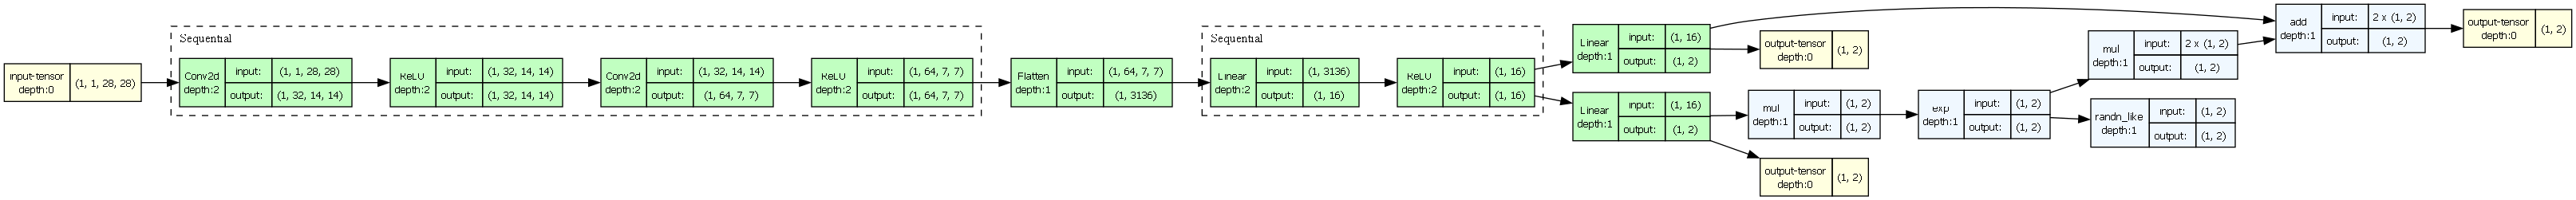

In [36]:
model_graphq = draw_graph(vae_encoder, input_size=(1, 1, 28, 28), expand_nested=True, graph_dir="LR")
model_graphq.resize_graph(scale=3)

model_graphq.visual_graph.render("vae_encoder", format="png")
display(Image(filename="vae_encoder.png"))

**Expected Output**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/qF7qRah.png" width="800">

---
## 2 - VAE Decoder

Decoder model for VAE is exactly the same as the previous Vanilla Decoder, so we can just instantiate a new `dencoder` model.

In [37]:
vae_decoder = ConvAE_Decoder().to(device)

---
## 3 - Variational-AutoEncoder

Now instantiate VAE model = VAE Encoder + VAE Decoder

---
#### <font color='red'>**EXERCISE:** </font>
    build the full VAE model
    - complete the layer and building blocks definition
    - complete the `forward` function


In [38]:
class VariationalAutoencoder(nn.Module):
    def __init__(self, encoder, decoder):
        super(VariationalAutoencoder, self).__init__()
        # check DCAE class
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x):

        # pass x through self.encoder()
        z, mean, log_var = self.encoder(x)

        # pass z through self.decoder()
        x_recon = self.decoder(z)

        return x_recon, mean, log_var

Instantiate `vae` model, and print the model architecture using `clean_summary` function


In [39]:
vae_model = VariationalAutoencoder(vae_encoder, vae_decoder).to(device)

clean_summary(vae_model, input_size=(1, 1, 28, 28), depth=2)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
VariationalAutoencoder                                                                       --
├─VAE_Encoder: 1-1                                                                           --
│    └─Sequential: 2-1                   [1, 1, 28, 28]            [1, 64, 7, 7]             18,816
│    └─Flatten: 2-2                      [1, 64, 7, 7]             [1, 3136]                 --
│    └─Sequential: 2-3                   [1, 3136]                 [1, 16]                   50,192
│    └─Linear: 2-4                       [1, 16]                   [1, 2]                    34
│    └─Linear: 2-5                       [1, 16]                   [1, 2]                    34
├─ConvAE_Decoder: 1-2                                                                        --
│    └─Sequential: 2-6                   [1, 2]                    [1, 3136]                 9,408
│    └─Sequential: 2-7  

**EXPECTED OUTPUT**:
<pre>
===================================================================================================================
Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
===================================================================================================================
VariationalAutoencoder                                                                       --
├─VAE_Encoder: 1-1                                                                           --
│    └─Sequential: 2-1                   [1, 1, 28, 28]            [1, 64, 7, 7]             18,816
│    └─Flatten: 2-2                      [1, 64, 7, 7]             [1, 3136]                 --
│    └─Sequential: 2-3                   [1, 3136]                 [1, 16]                   50,192
│    └─Linear: 2-4                       [1, 16]                   [1, 2]                    34
│    └─Linear: 2-5                       [1, 16]                   [1, 2]                    34
├─ConvAE_Decoder: 1-2                                                                        --
│    └─Sequential: 2-6                   [1, 2]                    [1, 3136]                 9,408
│    └─Sequential: 2-7                   [1, 64, 7, 7]             [1, 1, 28, 28]            55,681
===================================================================================================================
Total params: 134,165
Trainable params: 134,165

Visualize the network architecture


(process:6748): Pango-WARNING **: 19:37:26.991: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


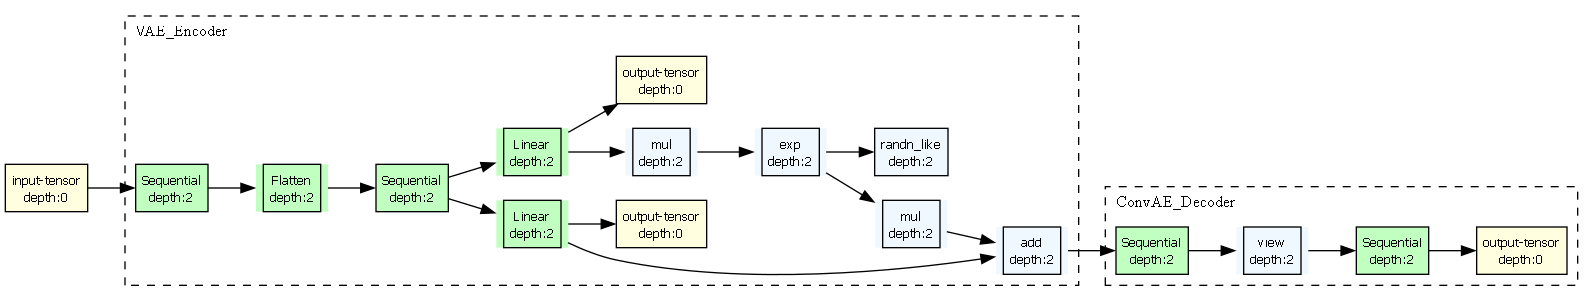

In [40]:
model_graphq = draw_graph(vae_model, input_size=(1, 1, 28, 28), expand_nested=True, show_shapes=False, depth=2, graph_dir="LR")
model_graphq.resize_graph(scale=3)

model_graphq.visual_graph.render("vae_model", format="png")
display(Image(filename="vae_model.png"))

**Expected Output**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/NFms5Lp.png" width="800">

---
## 4 - Train Variational AutoEncoder

Next to train the Variational AutoEncoder

---
### a. Define Loss


<center>
<img src='https://miro.medium.com/max/2080/1*L1klrEWx4Y5Bz6qMqTbwAQ@2x.png' width=60%>
</center>

VAEs train by maximizing the evidence lower bound (ELBO) on the marginal log-likelihood:

$$\log p(x) \ge \text{ELBO} = \mathbb{E}_{q(z|x)}\left[\log \frac{p(x, z)}{q(z|x)}\right].$$

then we calculate the KL term to optimize it, thus we have
$$
D_{KL} = \frac{1}{2}\sum_k\Big(\exp(\Sigma(X))+\mu^2(X)-1-\Sigma(X)\Big)
$$

Now to calculate the total loss is defined by

    VAE loss = mse_loss + kl_loss


In [41]:
def vae_loss_function(encoder_outputs, x):
    x_recon, mean, log_var = encoder_outputs
    # Reconstruction Loss (MSE Loss with binary scaling on total pixel per image)
    recon_loss = nn.functional.mse_loss(x_recon, x, reduction='sum') / x.size(0)

    # KL Divergence Loss
    kl_loss = -0.5 * torch.sum(1 + log_var - mean.pow(2) - log_var.exp()) / x.size(0)

    return recon_loss + kl_loss

---
#### <font color='red'>**AUTOGRADE (jangan dihapus):**</font> sanity check forward pass VAE dengan bobot KL personalisasi NIM


In [42]:
# --- AUTOGRADECHECK05: sanity check forward pass VAE + loss dengan bobot KL ---
# --- personalisasi NIM sendiri (BETA_MULT dari cell AUTOGRADESEED05). ---
# Cuma 1 forward pass di 32 sampel test, model belum/tidak perlu dilatih -
# murni memverifikasi forward pass (encoder -> sampling -> decoder) dan
# fungsi loss berjalan tanpa error, dan memakai BETA_MULT milik NIM sendiri
# (bukan disalin dari mahasiswa lain).
def vae_loss_function_beta(encoder_outputs, x, beta):
    x_recon, mean, log_var = encoder_outputs
    recon_loss = nn.functional.mse_loss(x_recon, x, reduction='sum') / x.size(0)
    kl_loss = -0.5 * torch.sum(1 + log_var - mean.pow(2) - log_var.exp()) / x.size(0)
    return recon_loss + beta * kl_loss

print("BETA_MULT yang dipakai (personalisasi NIM):", BETA_MULT)

vae_model.eval()
with torch.no_grad():
    sample_x = torch.tensor(x_test[:32]).unsqueeze(1).to(device)
    encoder_outputs = vae_model(sample_x)
    own_beta_loss = vae_loss_function_beta(encoder_outputs, sample_x, BETA_MULT)

print("Sanity loss (bobot KL personalisasi NIM):", own_beta_loss.item())


BETA_MULT yang dipakai (personalisasi NIM): 1.03
Sanity loss (bobot KL personalisasi NIM): 165.72760009765625


---
### b. Train DC-VAE
Then train the model for 50 epochs.
We'll use MNIST test set for validation

Training will take about 10 minutes. Just sit back and enjoy some snacks!

In [43]:
vae_optimizer = optim.Adam(vae_model.parameters(), lr=1e-3)

epochs = 50
base_dir_vae = 'conv_vae'

vae_history = train_model(vae_model, train_loader, test_loader,
                          vae_loss_function, vae_optimizer, epochs,
                          base_dir_vae)

Start Training


Epoch [1/50], Train Loss: 69.2174, Val Loss: 53.2591


Epoch [2/50], Train Loss: 50.8743, Val Loss: 49.8778


Epoch [4/50], Train Loss: 49.2251, Val Loss: 49.1669


Epoch [6/50], Train Loss: 48.7646, Val Loss: 48.8921


Epoch [8/50], Train Loss: 48.3453, Val Loss: 48.5442


... (17 outputs left out)

Epoch [44/50], Train Loss: 44.2352, Val Loss: 44.3472


Epoch [46/50], Train Loss: 44.1635, Val Loss: 44.3247


Epoch [48/50], Train Loss: 44.0759, Val Loss: 44.0610


Epoch [50/50], Train Loss: 44.0330, Val Loss: 44.0991
Training Done


**EXPECTED OUTPUT**:
<pre>
Loss should start at around 70 and ends at around 44 in 50 epochs (bisa sedikit
berbeda tergantung versi torch/seed random; yang penting turun monoton, bukan stuck).
Train more to get better result.


---
### c. Visualize Loss History

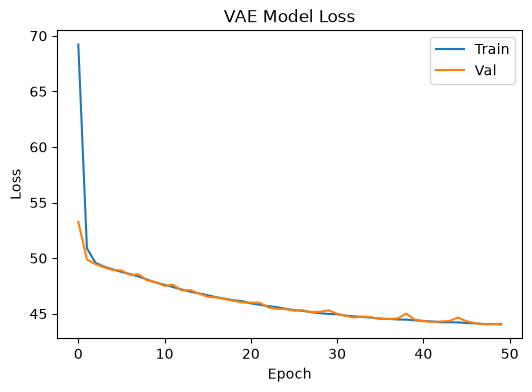

In [44]:
plot_loss(vae_history, title='VAE Model Loss')

---
## 5 - Visualize Generated Images

Now let's visualize the result

---
### a. Latent Space Distribution

Plots labels and MNIST digits as function of 2-dim latent vector

You should see that now the latent vector is more smoothly distributed across the space

z range: (-3.274181365966797, 3.86891508102417)


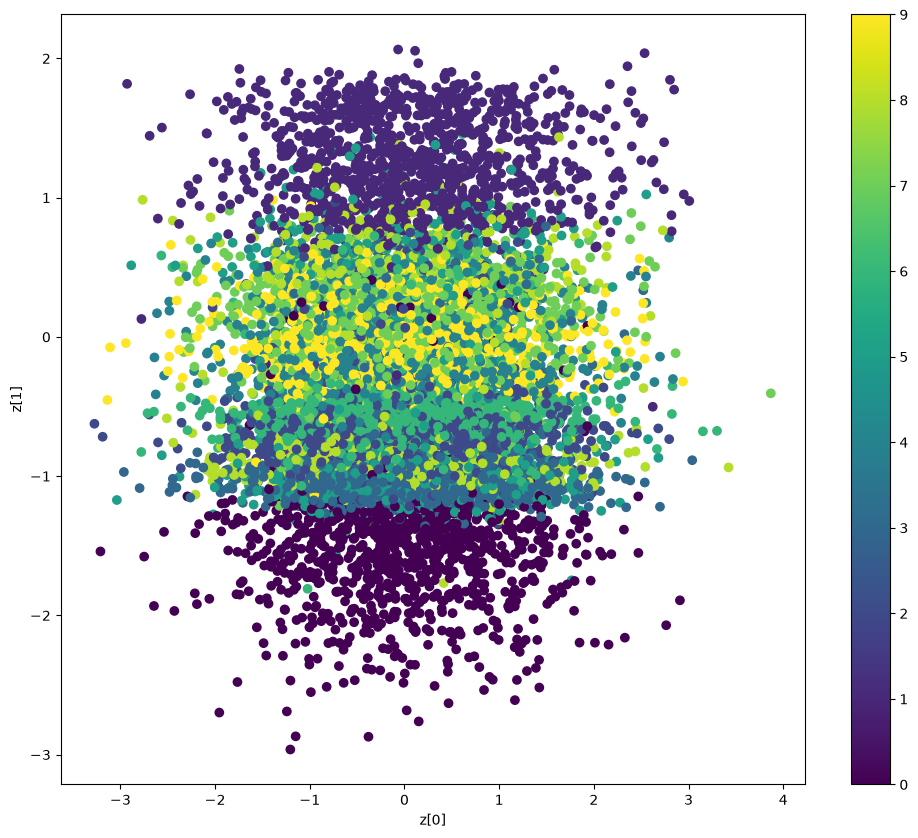

In [45]:
plot_latent_space(vae_encoder, x_test, y_test, vae=True)

**EXPECTED OUTPUT**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/ZbS52BM.png" height="300">

---
### b. Randomly Generated

Now we skip directly to generate &nbsp;$5$&nbsp; new images from a random latent vector &nbsp;$z$&nbsp;

You should see that the result is better

The network is able to generate new image from random input

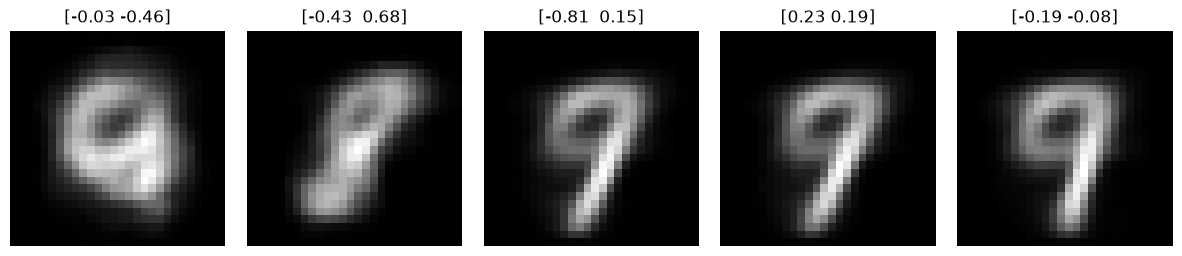

In [46]:
generate_image(vae_decoder, z_range=(-1, 1))

**EXPECTED OUTPUT**:
<pre>
output image should be something like this.

<img src="https://i.imgur.com/xvqn17u.png" width="400">

But what happened if we try to widen the vector random range to $(-5..5)$?

You might see that the image is much better that using Vanilla AutoEncoder, even though the network is not trained to generate image from that range

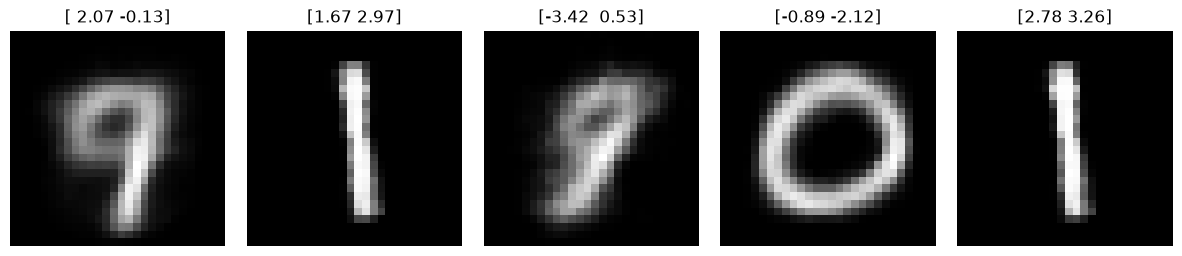

In [47]:
generate_image(vae_decoder, z_range=(-5, 5))

**EXPECTED OUTPUT**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/vugdK7W.png" width="400">

You can try to generate single image by running the cell below

you can use predefined latent vector or generate a random vector

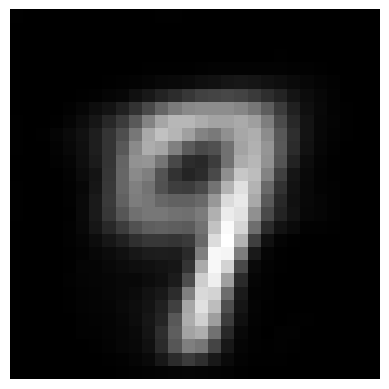

In [48]:
z_sample = np.array([[0,0]])

vae_decoder.eval()
with torch.no_grad():
    z_sample = torch.tensor(z_sample, dtype=torch.float32).to(device)
    x_decoded = vae_decoder(z_sample).cpu().numpy()
digit = x_decoded.reshape(28, 28)
plt.imshow(digit, cmap='gray')
plt.axis('off')
plt.show()

---
### c. Plot Interpolation

Next let's generate the image interpolation generated from a range of latent vectors

First we generate $10\times 10$ image ranged from $(-1..1)$

You may see that the interpolation is done more smoothly

range:( -1 : 1 )


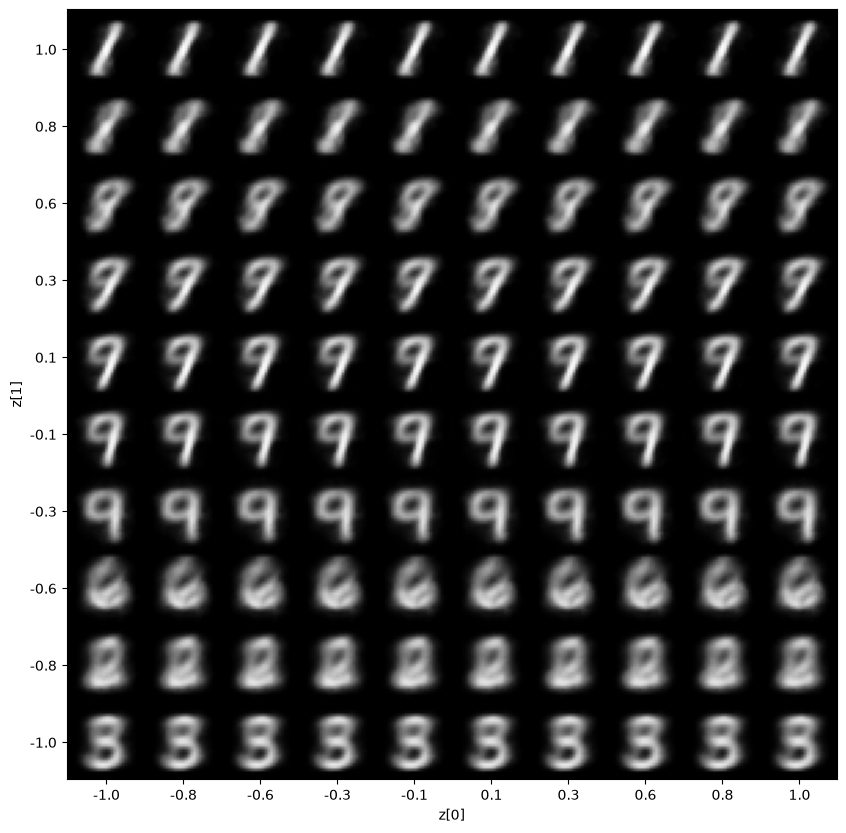

In [49]:
plot_interpolating(vae_decoder, n=10)

**EXPECTED OUTPUT**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/ZaIYgx4.png" height="300">

Now let's try to widen the range. For that we deepen the interpolation to $20\times 20$

You might see that the interpolation still results smooth images across wide range

range:( -5 : 5 )


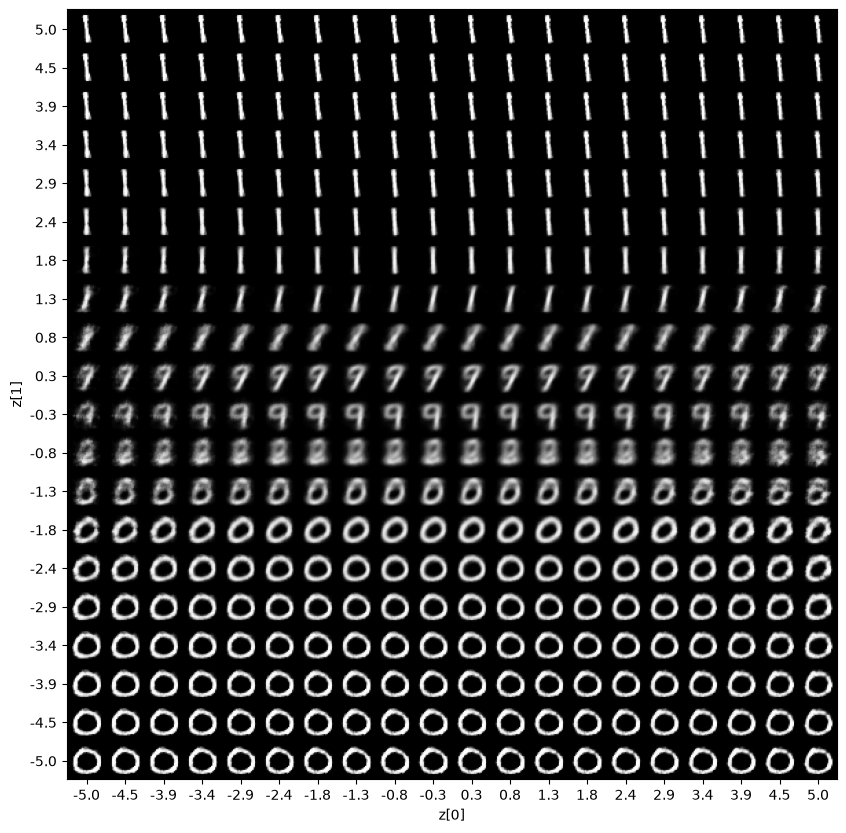

In [50]:
plot_interpolating(vae_model.decoder, n=20, z_range=(-5, 5))

**EXPECTED OUTPUT**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/HvsAlWe.png" height="300">

---
### d. Generate GIF

Now this just for fun, we combine the saved image generated each epoch while training into a GIF animation

open the result in Files tab

In [51]:
show_gif(base_dir_vae, 'var_autoenc.gif')

GIF saved as var_autoenc.gif


---
---

# Congratulation, You've Completed Exercise 5

<p>Copyright &copy;  <a href=https://www.linkedin.com/in/andityaarifianto/>2026 - ADF</a> </p>

![footer](https://i.imgur.com/UU76cTP.png)